# Drug Galaxy: 3D layout and clustering (ML component)

1. **PCA**: a faithful 3D view with labeled axes
2. **t-SNE**: a clustered 3D view, with perplexity tuned
3. **K-means**: the algorithm's own groups, compared with the real ones

Output: `data/processed/coords.csv` with every drug's 3D positions and cluster, for the website.

In [4]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

drugs = pd.read_csv("../data/processed/drugs_clean.csv", keep_default_na=False)
drugs = drugs[drugs["heavy_atoms"] >= 6].reset_index(drop=True)

# fingerprints as a numpy array: one row per drug, 2048 columns of 0/1
fp_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
X = np.array([fp_gen.GetFingerprintAsNumPy(Chem.MolFromSmiles(s)) for s in drugs["smiles"]])
print("X shape:", X.shape)

X shape: (2136, 2048)


### Primary group (for coloring)

Drugs in several groups get colored by one of them. `clean.py` sorted the codes alphabetically, so this takes the first one alphabetically. The tooltip on the website can list all of them.


In [5]:
drugs["primary_group"] = drugs["atc_groups"].apply(lambda g: g.split(";")[0] if g != "" else "unclassified")
drugs["primary_group"].value_counts()

primary_group
unclassified    344
N               337
L               223
C               217
A               214
J               198
D               117
R                92
M                86
G                79
V                68
B                52
P                45
S                41
H                23
Name: count, dtype: int64

## 1. PCA to 3D

`explained_variance_ratio_` is the share of total variation each axis captures. Expect small numbers: 2,048 switches don't squash well into 3.

In [6]:
pca3 = PCA(n_components=3, random_state=42)
pca_xyz = pca3.fit_transform(X)

for i, share in enumerate(pca3.explained_variance_ratio_):
    print(f"PC{i+1}: {share:.1%} of variation")
print(f"total: {pca3.explained_variance_ratio_.sum():.1%}")

PC1: 3.5% of variation
PC2: 2.4% of variation
PC3: 2.0% of variation
total: 8.0%


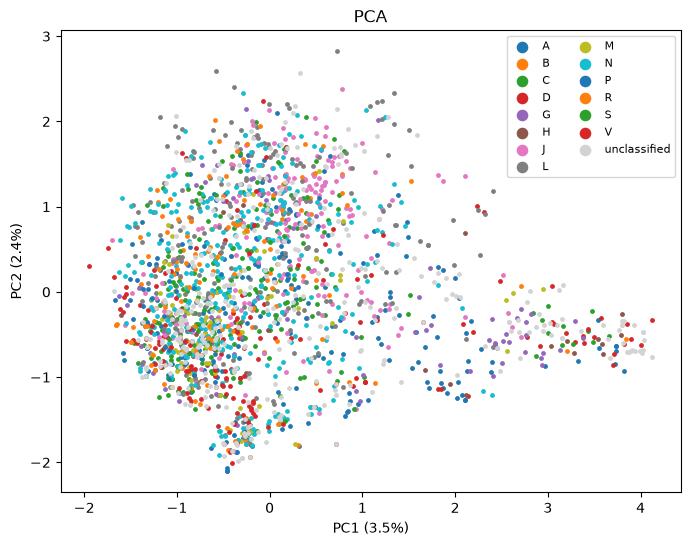

In [7]:
# quick 2D check: PC1 vs PC2, colored by group
def plot_2d(xy, title, xlabel, ylabel):
    plt.figure(figsize=(8, 6))
    for g in sorted(drugs["primary_group"].unique()):
        mask = drugs["primary_group"] == g
        color = "lightgray" if g == "unclassified" else None
        plt.scatter(xy[mask, 0], xy[mask, 1], s=6, label=g, color=color)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.legend(markerscale=3, fontsize=8, ncol=2)
    plt.show()

r = pca3.explained_variance_ratio_
plot_2d(pca_xyz, "PCA", f"PC1 ({r[0]:.1%})", f"PC2 ({r[1]:.1%})")

## 2. PCA to 50 (input for K-means)

Keeps most of the information in far fewer numbers, which K-means handles better than raw 0/1 switches.

In [8]:
pca50 = PCA(n_components=50, random_state=42)
X50 = pca50.fit_transform(X)
print(f"50 components keep {pca50.explained_variance_ratio_.sum():.1%} of the variation")

50 components keep 39.9% of the variation


## 3. t-SNE to 3D, with perplexity tuned

Run on the raw fingerprints with **Jaccard distance** (= 1 − Tanimoto), so the layout uses the same similarity as the neighbor test.

To pick perplexity, try three values and score each with **trustworthiness**: how well each drug's 10 nearest neighbors in 3D match its real nearest neighbors (1.0 = perfect). Takes a few minutes.

In [10]:
X_bool = X.astype(bool)     # jaccard expects True/False

tsne_runs = {}
for perp in [10, 30, 50]:
    tsne = TSNE(n_components=3, perplexity=perp, metric="jaccard", init="random", random_state=42)
    xyz = tsne.fit_transform(X_bool)
    score = trustworthiness(X_bool, xyz, n_neighbors=10, metric="jaccard")
    tsne_runs[perp] = (xyz, score)
    print(f"perplexity {perp}: trustworthiness {score:.3f}")

# for comparison: how trustworthy is the PCA view?
print(f"PCA (3D):      trustworthiness {trustworthiness(X_bool, pca_xyz, n_neighbors=10, metric='jaccard'):.3f}")

/opt/miniconda3/envs/dvjupyter/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


perplexity 10: trustworthiness 0.944


/opt/miniconda3/envs/dvjupyter/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


perplexity 30: trustworthiness 0.944


/opt/miniconda3/envs/dvjupyter/lib/python3.11/site-packages/sklearn/metrics/pairwise.py:2480: DataConversionWarning: Data was converted to boolean for metric jaccard
  warnings.warn(msg, DataConversionWarning)


perplexity 50: trustworthiness 0.940
PCA (3D):      trustworthiness 0.818


using perplexity 30


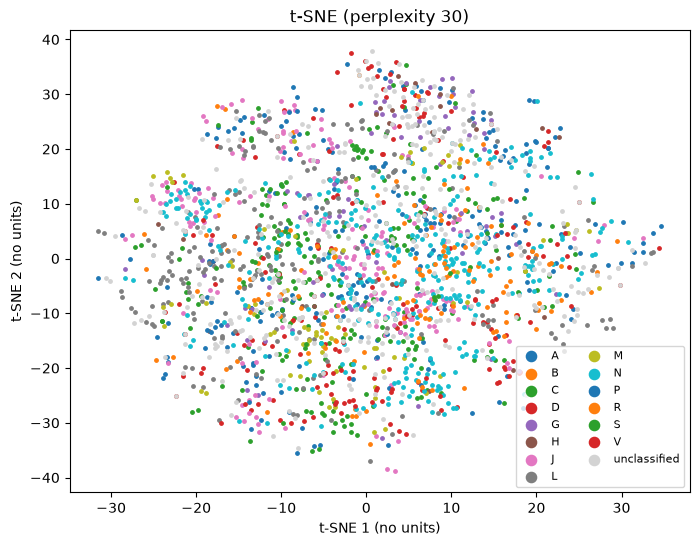

In [11]:
best_perp = max(tsne_runs, key=lambda p: tsne_runs[p][1])
tsne_xyz = tsne_runs[best_perp][0]
print("using perplexity", best_perp)

plot_2d(tsne_xyz, f"t-SNE (perplexity {best_perp})", "t-SNE 1 (no units)", "t-SNE 2 (no units)")

## 4. K-means

Clusters drugs using chemistry only, then checks how well the clusters match the real groups.

- **Silhouette** (−1 to 1): how well-separated the clusters are. Higher is better.
- **ARI** (0 = random, 1 = perfect): how well the clusters line up with the real groups. Only classified drugs are compared.

In [13]:
classified = (drugs["primary_group"] != "unclassified").values

for k in [8, 14, 20, 30]:
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X50)
    sil = silhouette_score(X50, labels)
    ari = adjusted_rand_score(drugs.loc[classified, "primary_group"], labels[classified])
    print(f"k={k:2d}  silhouette {sil:.3f}   ARI vs groups {ari:.3f}")

k= 8  silhouette 0.054   ARI vs groups 0.039
k=14  silhouette 0.073   ARI vs groups 0.060
k=20  silhouette 0.085   ARI vs groups 0.044
k=30  silhouette 0.097   ARI vs groups 0.055


Use **k = 14** for the main comparison, since it matches the 14 groups.

In [14]:
K = 14
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
drugs["cluster"] = kmeans.fit_predict(X50)

### Which clusters are pure, and which mix groups?

For each cluster: its size, its most common group, what share of its classified drugs are in that group, and how many different groups appear. Low share = a chemical family used for different things.

In [15]:
rows = []
for c in range(K):
    members = drugs[(drugs["cluster"] == c) & classified]
    counts = members["primary_group"].value_counts()
    rows.append({
        "cluster": c,
        "size": int((drugs["cluster"] == c).sum()),
        "top_group": counts.index[0],
        "top_share": counts.iloc[0] / counts.sum(),
        "n_groups": len(counts),
        "examples": ", ".join(members["name"].head(4).str.title()),
    })

clusters = pd.DataFrame(rows).sort_values("top_share", ascending=False).reset_index(drop=True)
clusters.round(2)

,cluster,size,top_group,top_share,n_groups,examples
0,11,62,J,1.00,1,"Ampicillin, Cefadroxil, Penicillin V, Cephalor..."
1,12,116,N,0.52,8,"Bilastine, Fipexide, Dyclonine, Triprolidine"
2,3,96,G,0.47,11,"Ethylestrenol, Brexanolone, Dienogest, Ethinyl..."
3,10,68,A,0.42,10,"Lymecycline, Naldemedine, Cholic Acid, Taururs..."
4,8,190,L,0.40,14,"Binimetinib, Palbociclib, Paroxetine, Tepotinib"
5,13,56,D,0.39,6,"Halobetasol Propionate, Diflorasone Diacetate,..."
6,9,311,N,0.36,14,"Diazepam, Bretylium, Butenafine, Hexachlorophene"
7,5,51,L,0.34,6,"Clarithromycin, Doxorubicin, Epirubicin, Ampho..."
8,0,65,A,0.30,9,"Ipragliflozin, Dihydrostreptomycin, Uridine Tr..."
9,1,147,L,0.28,12,"Erlotinib, Ivabradine, Donepezil, Brigatinib"


In [16]:
# full cross-table: rows = clusters, columns = groups
pd.crosstab(drugs.loc[classified, "cluster"], drugs.loc[classified, "primary_group"])

primary_group,A,B,C,D,G,H,J,L,M,N,P,R,S,V
cluster,,,,,,,,,,,,,,
0,17,2,3,3,0,0,14,13,1,0,0,0,2,2
1,13,4,21,6,4,2,6,37,10,18,6,5,0,0
2,35,11,18,7,6,3,25,19,9,52,8,6,4,29
3,8,0,3,5,29,3,0,2,3,4,3,0,1,1
4,17,10,26,0,9,0,23,15,4,17,1,4,7,7
5,6,0,6,4,0,0,12,15,0,0,1,0,0,0
6,32,11,80,13,14,3,5,18,35,58,11,25,11,16
7,14,2,23,8,3,0,14,13,6,5,0,2,7,1
8,8,8,7,8,2,2,34,64,1,16,1,4,3,3


In [17]:
coords = drugs[["chembl_id", "name", "atc_groups", "primary_group", "cluster"]].copy()
coords[["pca_x", "pca_y", "pca_z"]] = pca_xyz
coords[["tsne_x", "tsne_y", "tsne_z"]] = tsne_xyz
coords.to_csv("../data/processed/coords.csv", index=False)

# keep the axis labels for the website
print("PCA axis labels:", [f"PC{i+1} ({s:.1%})" for i, s in enumerate(pca3.explained_variance_ratio_)])
print("t-SNE perplexity:", best_perp)

PCA axis labels: ['PC1 (3.5%)', 'PC2 (2.4%)', 'PC3 (2.0%)']
t-SNE perplexity: 30
